EVA-Guard — Exploration du dataset merged
Ce notebook réalise une analyse exploratoire (EDA) de dataset_merged.csv avant le feature engineering et l'entraînement.
Objectifs
- vérifier la structure, les types et la qualité des données ;
- analyser la distribution des classes par session et par nœud ;
- étudier les valeurs manquantes et les variables constantes ;
- comparer les métriques système, Geth, Beacon et Validator entre scénarios ;
- observer les évolutions temporelles pour un nœud donné.
Le notebook ne modifie pas le dataset source. Il ne réalise ni imputation, ni encodage de la cible, ni entraînement ML.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Le notebook se trouve dans ml/notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks" and PROJECT_ROOT.parent.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif (PROJECT_ROOT / "monitoring-rust").exists():
    pass
elif (PROJECT_ROOT.parent / "monitoring-rust").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "ml" / "data" / "raw" / "dataset_merged.csv"

# Si le notebook est lancé depuis ml/notebooks, ce chemin alternatif fonctionne aussi.
if not DATA_PATH.exists():
    DATA_PATH = Path("../../monitoring-rust/data") / "dataset_merged.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())


Project root: /home/mohamed-amine/Downloads/EVA_ethereum
Dataset path: /home/mohamed-amine/Downloads/EVA_ethereum/ml/data/raw/dataset_merged.csv
Dataset exists: True


2. Chargement des données

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset introuvable : {DATA_PATH}\n"
        "Place dataset_merged.csv dans ml/data/raw/."
    )

df = pd.read_csv(DATA_PATH)

required_columns = {"timestamp", "node_id", "scenario", "session"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Colonnes obligatoires absentes : {missing_columns}")

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")

print(f"Shape : {df.shape[0]} lignes × {df.shape[1]} colonnes")
display(df.head())


Shape : 2160 lignes × 66 colonnes


,timestamp,node_id,scenario,session,geth_peer_count,geth_admin_peer_count,geth_peer_details_available,geth_new_peers,geth_disconnected_peers,geth_peer_churn_count,...,validator_blocks_proposed_total,validator_block_proposal_failures_total,validator_missed_proposals_total,validator_validators_total,validator_validators_enabled,validator_attester_duties,validator_proposer_duties,validator_beacon_node_online,validator_attestation_effectiveness,validator_proposal_effectiveness
0,2026-11-25 06:00:07+00:00,node-01,NORMAL,session1,4.0,4.0,True,NaN,NaN,NaN,...,13.0,0.0,NaN,1.0,1.0,1.0,6.0,True,NaN,NaN
1,2026-11-25 06:00:12+00:00,node-01,NORMAL,session1,4.0,4.0,True,0.0,0.0,0.0,...,13.0,0.0,NaN,1.0,1.0,1.0,6.0,True,NaN,NaN
2,2026-11-25 06:00:17+00:00,node-01,NORMAL,session1,4.0,4.0,True,0.0,0.0,0.0,...,13.0,0.0,NaN,1.0,1.0,1.0,6.0,True,NaN,NaN
3,2026-11-25 06:00:22+00:00,node-01,NORMAL,session1,4.0,4.0,True,0.0,0.0,0.0,...,13.0,0.0,NaN,1.0,1.0,1.0,6.0,True,NaN,NaN
4,2026-11-25 06:00:27+00:00,node-01,NORMAL,session1,4.0,4.0,True,0.0,0.0,0.0,...,13.0,0.0,NaN,1.0,1.0,1.0,6.0,True,NaN,NaN


3. Structure générale et types

In [3]:
display(df.info())
display(df.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 66 columns):
 #   Column                                    Non-Null Count  Dtype              
---  ------                                    --------------  -----              
 0   timestamp                                 2160 non-null   datetime64[us, UTC]
 1   node_id                                   2160 non-null   str                
 2   scenario                                  2160 non-null   str                
 3   session                                   2160 non-null   str                
 4   geth_peer_count                           2160 non-null   float64            
 5   geth_admin_peer_count                     2160 non-null   float64            
 6   geth_peer_details_available               2160 non-null   bool               
 7   geth_new_peers                            2100 non-null   float64            
 8   geth_disconnected_peers                   2100 non-null   float64    

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
timestamp,2160,NaN,NaN,NaN,2026-11-25 06:19:04.500000+00:00,2026-11-25 06:00:07+00:00,2026-11-25 06:09:35.750000+00:00,2026-11-25 06:19:04.500000+00:00,2026-11-25 06:28:33.250000+00:00,2026-11-25 06:38:02+00:00,NaN
node_id,2160,5,node-01,432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scenario,2160,3,NORMAL,720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session,2160,4,session1,540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geth_peer_count,2160.0,NaN,NaN,NaN,1.027778,0.0,0.0,1.0,1.0,4.0,1.202578
...,...,...,...,...,...,...,...,...,...,...,...
validator_attester_duties,2160.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,0.0
validator_proposer_duties,2160.0,NaN,NaN,NaN,6.4,2.0,5.0,6.0,9.0,10.0,2.393484
validator_beacon_node_online,2160,1,True,2160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
validator_attestation_effectiveness,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


4. Distribution des scénarios

,observations
scenario,
NORMAL,720
ECLIPSE,720
RPC_FLOODING,720


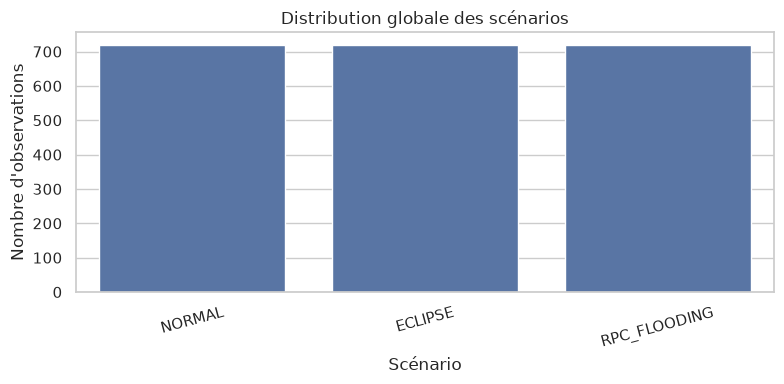

In [4]:
class_counts = df["scenario"].value_counts(dropna=False)
display(class_counts.to_frame("observations"))

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="scenario", order=class_counts.index)
plt.title("Distribution globale des scénarios")
plt.xlabel("Scénario")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


5. Répartition par session et par nœud

scenario,ECLIPSE,NORMAL,RPC_FLOODING
session,,,
session1,180,180,180
session2,180,180,180
session3,180,180,180
session4,180,180,180


scenario,ECLIPSE,NORMAL,RPC_FLOODING
node_id,,,
node-01,144,144,144
node-02,144,144,144
node-03,144,144,144
node-04,144,144,144
node-05,144,144,144


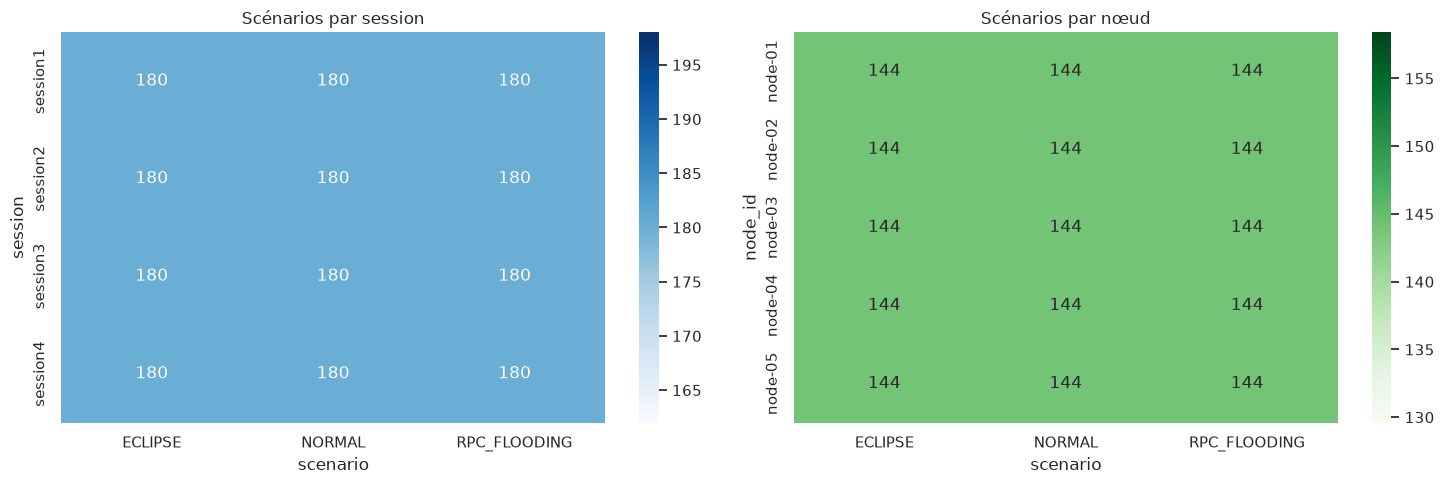

In [5]:
session_distribution = pd.crosstab(df["session"], df["scenario"])
node_distribution = pd.crosstab(df["node_id"], df["scenario"])

display(session_distribution)
display(node_distribution)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(session_distribution, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Scénarios par session")
sns.heatmap(node_distribution, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Scénarios par nœud")
plt.tight_layout()
plt.show()


6. Qualité des données : doublons et valeurs manquantes

Doublons sur ['timestamp', 'node_id', 'session'] : 0
Timestamps invalides : 0


,missing_count,missing_percent
geth_block_execution_ms,2160,100.00
beacon_inbound_peers,2160,100.00
validator_missed_attestations_last_epoch,2160,100.00
validator_missed_attestations_total,2160,100.00
validator_proposal_effectiveness,2160,100.00
validator_missed_proposals_total,2160,100.00
beacon_reorgs_total,2160,100.00
beacon_top_client_ratio,2160,100.00
beacon_unique_peer_clients,2160,100.00
validator_attestation_effectiveness,2160,100.00


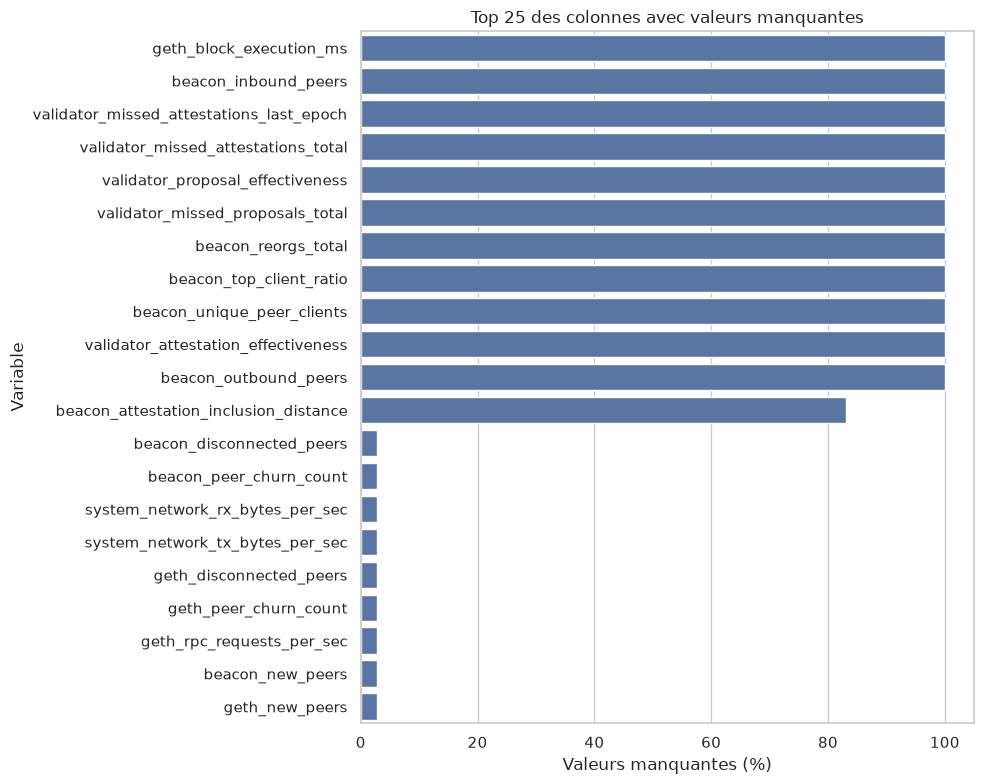

In [6]:
duplicate_keys = ["timestamp", "node_id", "session"]
print("Doublons sur", duplicate_keys, ":", df.duplicated(duplicate_keys).sum())
print("Timestamps invalides :", df["timestamp"].isna().sum())

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing[missing["missing_count"] > 0])

missing_plot = missing[missing["missing_count"] > 0].head(25)
plt.figure(figsize=(10, 8))
sns.barplot(data=missing_plot.reset_index(), x="missing_percent", y="index")
plt.title("Top 25 des colonnes avec valeurs manquantes")
plt.xlabel("Valeurs manquantes (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


7. Variables constantes et entièrement manquantes

In [7]:
metadata_cols = ["timestamp", "node_id", "scenario", "session"]
feature_cols = [c for c in df.columns if c not in metadata_cols]

all_missing = [c for c in feature_cols if df[c].isna().all()]
constant = [
    c for c in feature_cols
    if df[c].nunique(dropna=True) <= 1 and c not in all_missing
]

print("Colonnes entièrement manquantes :", len(all_missing))
display(pd.Series(all_missing, name="all_missing_columns").to_frame())

print("Colonnes constantes (hors colonnes entièrement vides) :", len(constant))
display(pd.Series(constant, name="constant_columns").to_frame())


Colonnes entièrement manquantes : 11


,all_missing_columns
0,geth_block_execution_ms
1,beacon_inbound_peers
2,beacon_outbound_peers
3,beacon_unique_peer_clients
4,beacon_top_client_ratio
5,beacon_reorgs_total
6,validator_missed_attestations_total
7,validator_missed_attestations_last_epoch
8,validator_missed_proposals_total
9,validator_attestation_effectiveness


Colonnes constantes (hors colonnes entièrement vides) : 25


,constant_columns
0,geth_peer_details_available
1,geth_network_listening
2,geth_txpool_pending
3,geth_txpool_queued
4,geth_rpc_available
5,geth_rpc_failed_requests_total
6,geth_is_synced
7,geth_block_tx_count
8,system_memory_total_mb
9,beacon_peer_count


8. Résumé statistique des variables numériques par scénario

In [8]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

summary = df.groupby("scenario")[numeric_cols].agg(["mean", "median", "std"])
display(summary)


geth_peer_count                  geth_admin_peer_count         \
                        mean median       std                  mean median   
scenario                                                                     
ECLIPSE             0.044444    0.0  0.295016              0.015278    0.0   
NORMAL              1.600000    1.0  1.200834              1.600000    1.0   
RPC_FLOODING        1.438889    1.0  1.161093              1.438889    1.0   

                       geth_new_peers                   \
                   std           mean median       std   
scenario                                                 
ECLIPSE       0.133592       0.011429    0.0  0.106368   
NORMAL        1.200834       0.000000    0.0  0.000000   
RPC_FLOODING  1.161093       0.025714    0.0  0.167183   

             geth_disconnected_peers  ... validator_attester_duties  \
                                mean  ...                       std   
scenario                              ...                             
ECLIPSE                     0.015714  ...                       0.0   
NORMAL                      0.000000  ...                       0.0   
RPC_FLOODING                0.000000  ...                       0.0   

             validator_proposer_duties                   \
                                  mean median       std   
scenario                                                  
ECLIPSE                            6.4    6.0  2.515266   
NORMAL                             6.4    6.0  2.405603   
RPC_FLOODING                       6.4    6.0  2.255822   

             validator_attestation_effectiveness             \
                                            mean median std   
scenario                                                      
ECLIPSE                                      NaN    NaN NaN   
NORMAL                                       NaN    NaN NaN   
RPC_FLOODING                                 NaN    NaN NaN   

             validator_proposal_effectiveness             
                                         mean median std  
scenario                                                  
ECLIPSE                                   NaN    NaN NaN  
NORMAL                                    NaN    NaN NaN  
RPC_FLOODING                              NaN    NaN NaN  

[3 rows x 162 columns]

9. Comparaison de métriques importantes entre scénarios

Métriques disponibles : ['geth_rpc_requests_per_sec', 'geth_rpc_latency_ms', 'system_cpu_usage_percent', 'system_network_rx_bytes_per_sec', 'system_network_tx_bytes_per_sec', 'system_tcp_established_connections', 'geth_peer_count', 'beacon_peer_count', 'beacon_unique_peer_ips', 'beacon_sync_distance', 'geth_latest_block_age_secs', 'beacon_finality_distance_epochs']


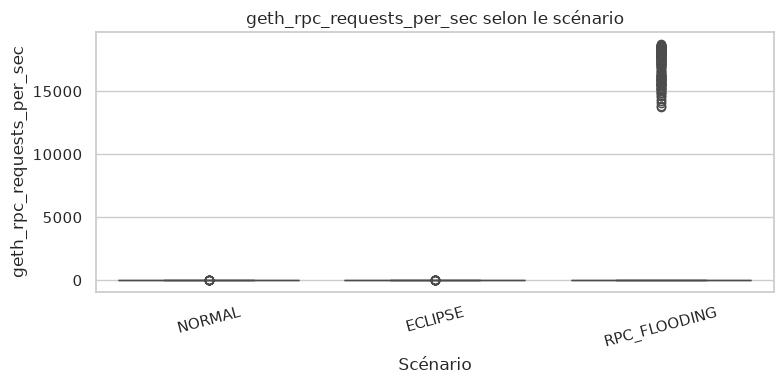

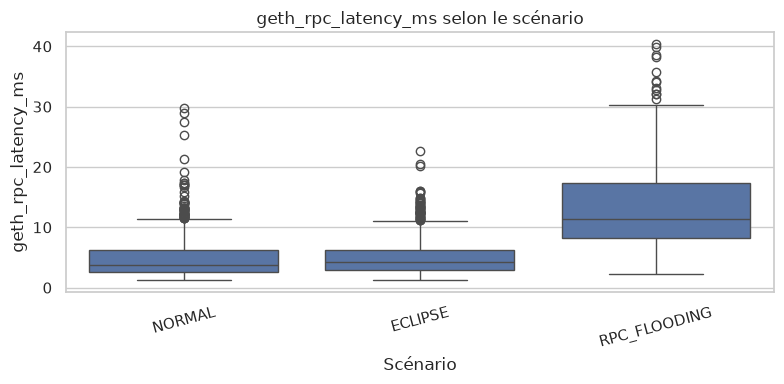

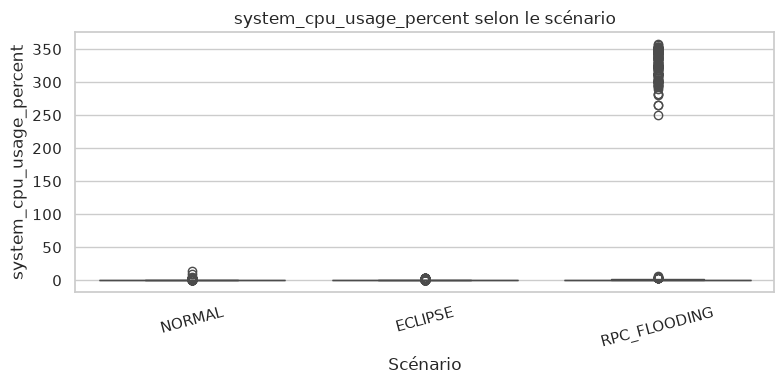

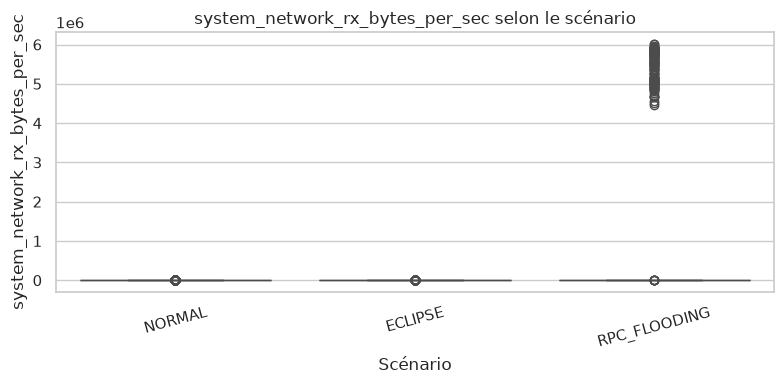

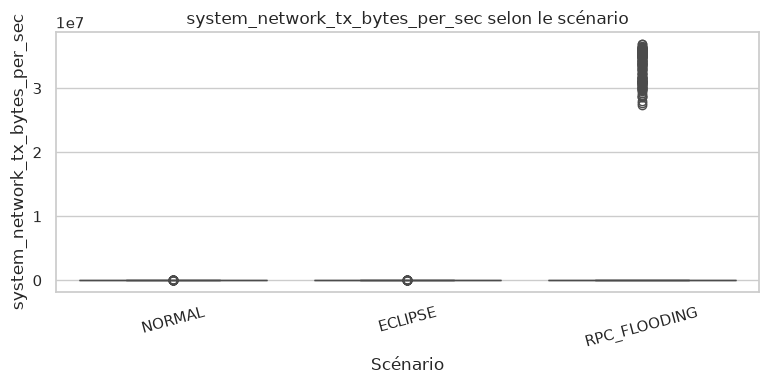

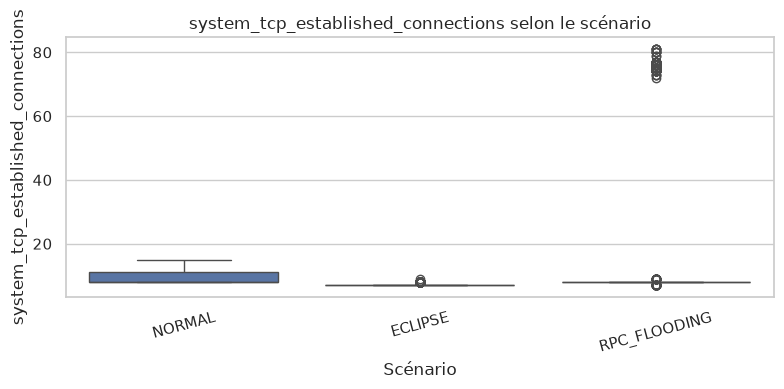

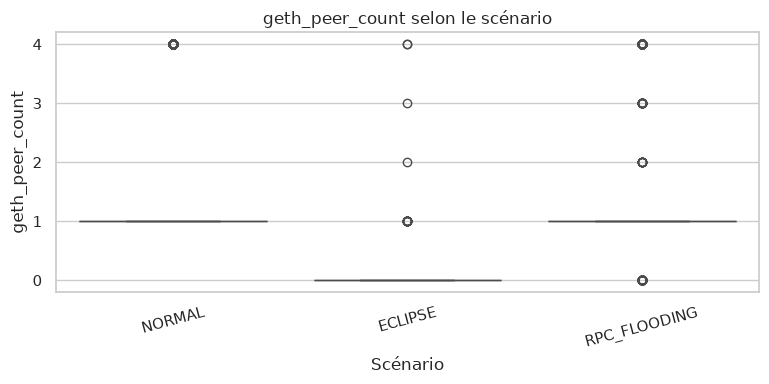

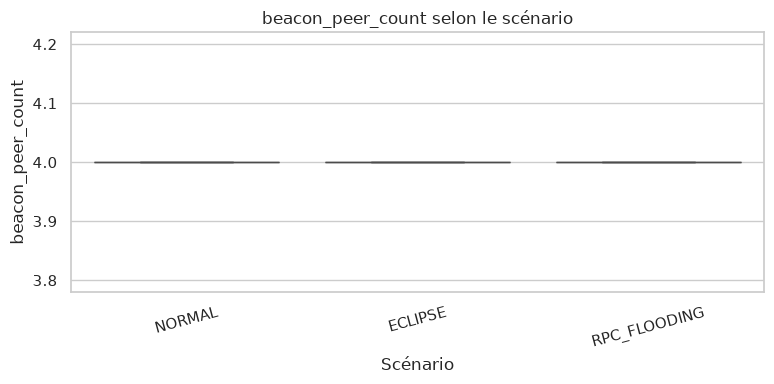

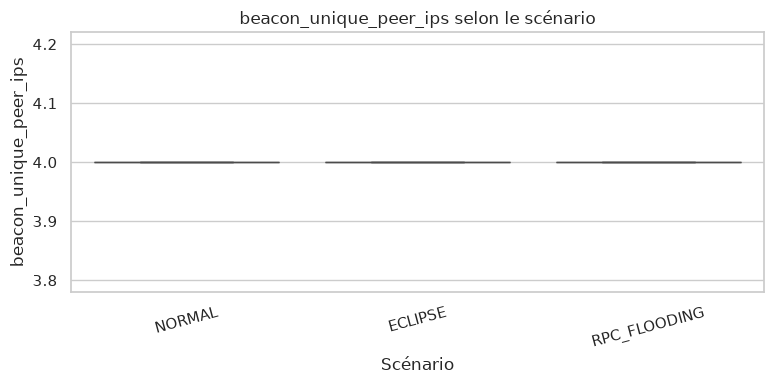

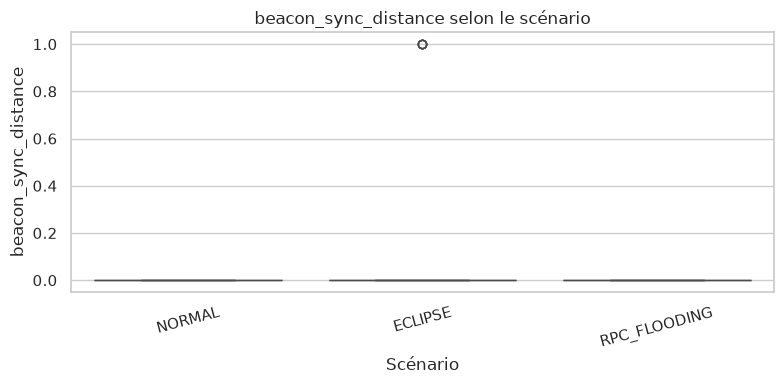

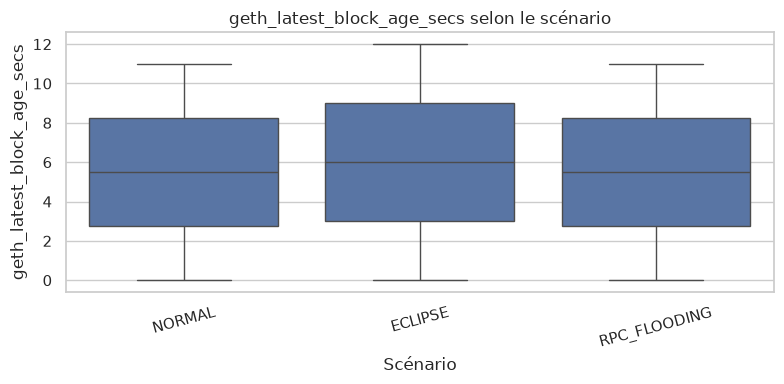

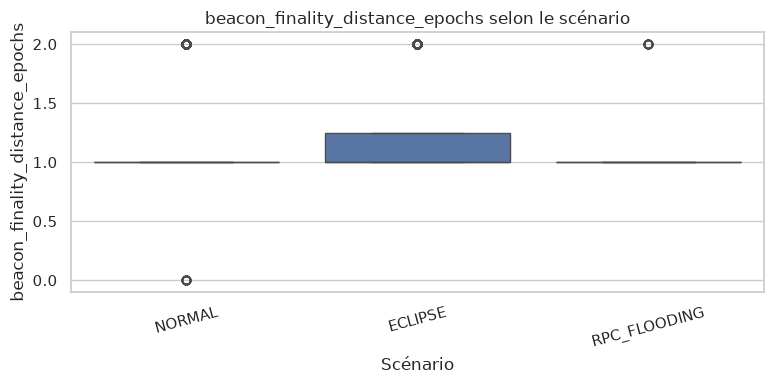

In [9]:
candidate_metrics = [
    "geth_rpc_requests_per_sec",
    "geth_rpc_latency_ms",
    "system_cpu_usage_percent",
    "system_network_rx_bytes_per_sec",
    "system_network_tx_bytes_per_sec",
    "system_tcp_established_connections",
    "geth_peer_count",
    "beacon_peer_count",
    "beacon_unique_peer_ips",
    "beacon_sync_distance",
    "geth_latest_block_age_secs",
    "beacon_finality_distance_epochs",
]

available_metrics = [c for c in candidate_metrics if c in df.columns]
print("Métriques disponibles :", available_metrics)

for metric in available_metrics:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="scenario", y=metric)
    plt.title(f"{metric} selon le scénario")
    plt.xlabel("Scénario")
    plt.ylabel(metric)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


10. Corrélations entre variables numériques

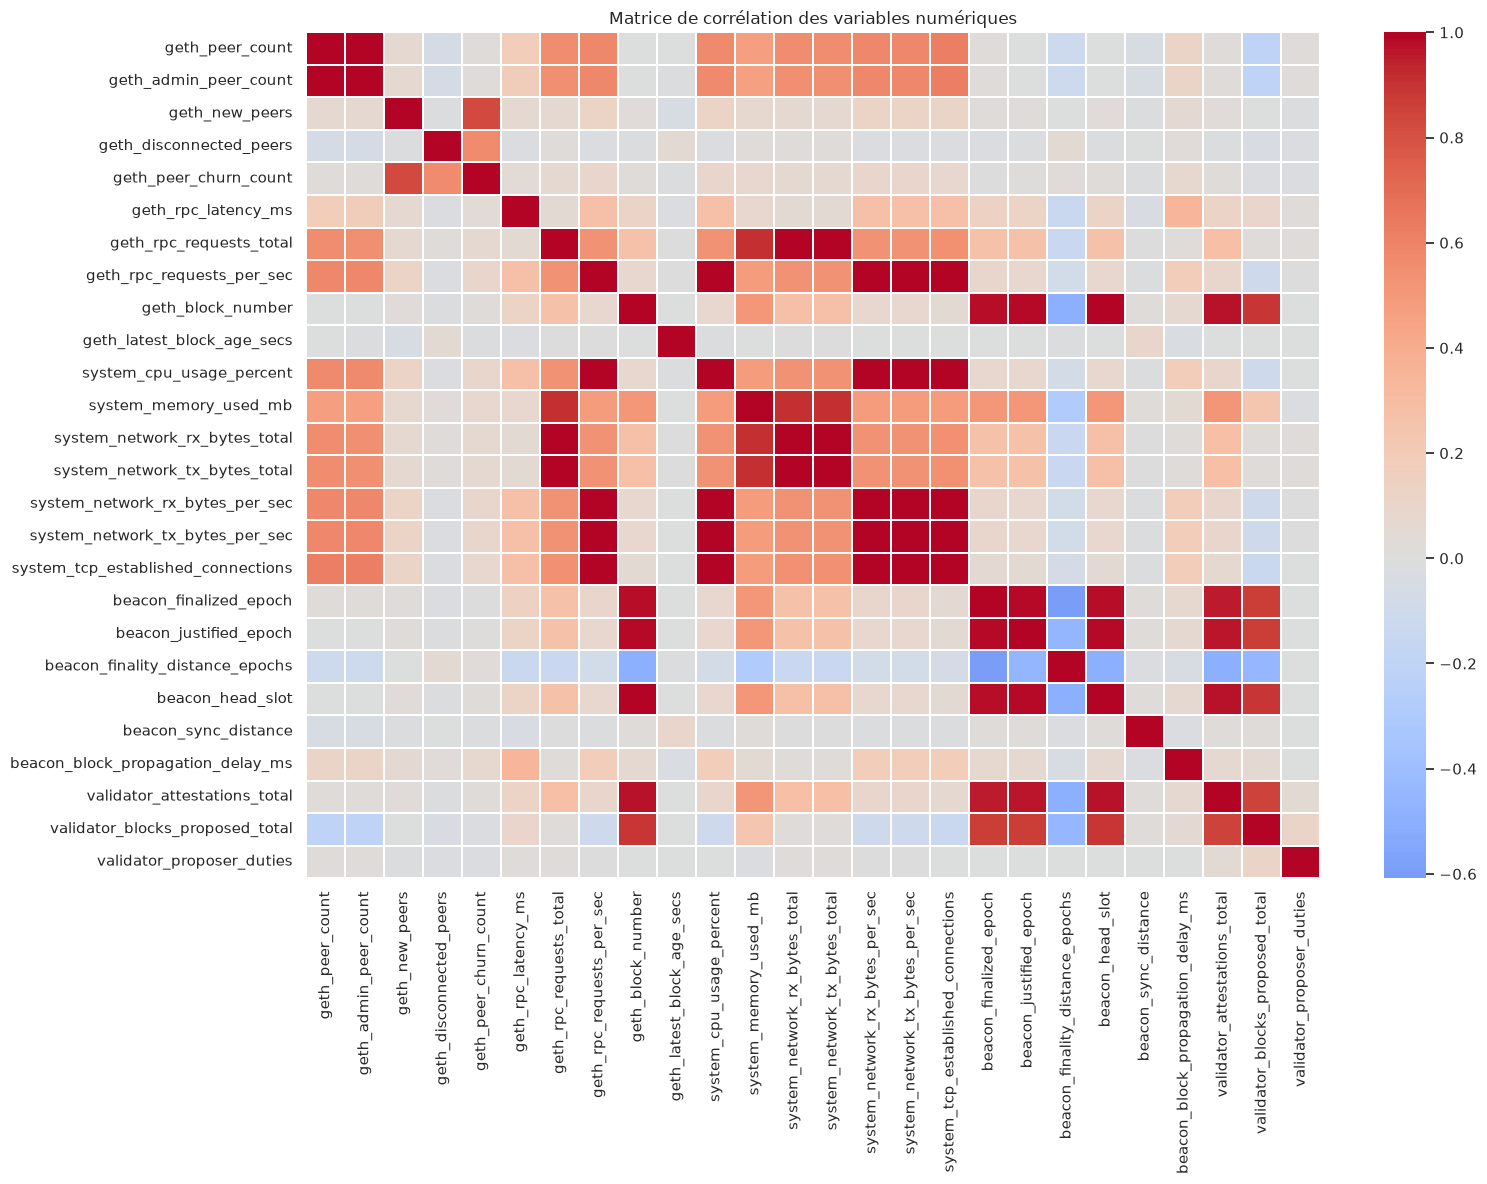

In [10]:
# Exclure les variables numériques constantes et celles entièrement vides.
numeric_df = df.select_dtypes(include="number")
usable_numeric = [
    c for c in numeric_df.columns
    if numeric_df[c].notna().any() and numeric_df[c].nunique(dropna=True) > 1
]

corr = numeric_df[usable_numeric].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.1)
plt.title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()


11. Évolution temporelle d'un nœud

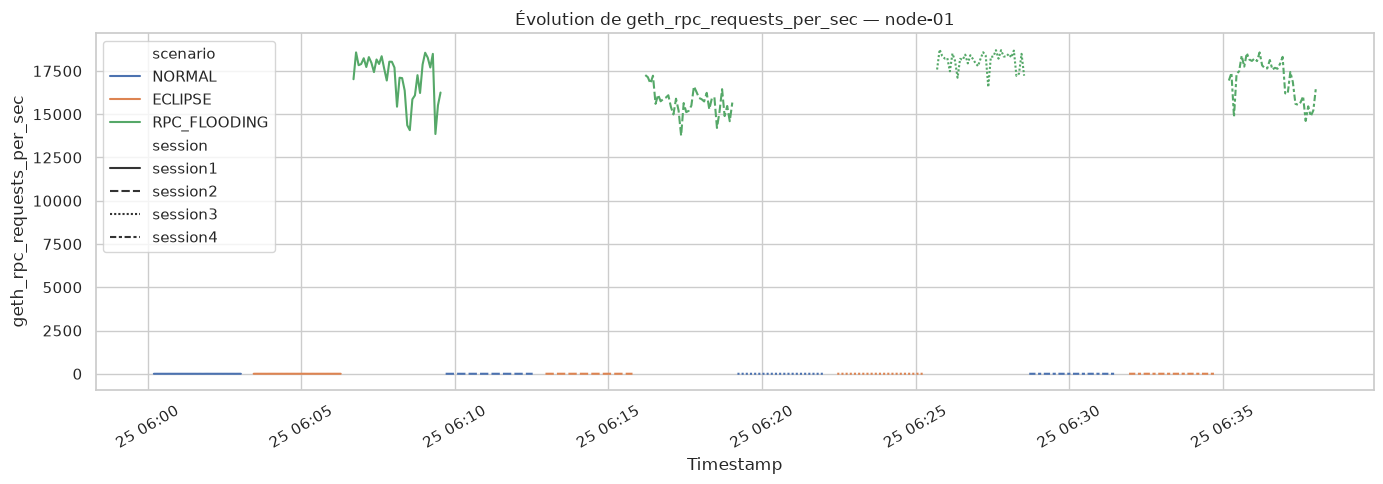

In [11]:
# Choisir un nœud et une métrique pour observer son évolution.
selected_node = sorted(df["node_id"].dropna().unique())[0]
selected_metric = "geth_rpc_requests_per_sec"

if selected_metric not in df.columns:
    raise ValueError(f"Métrique absente : {selected_metric}")

node_df = df[df["node_id"] == selected_node].sort_values("timestamp")

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=node_df,
    x="timestamp",
    y=selected_metric,
    hue="scenario",
    style="session",
    estimator=None
)
plt.title(f"Évolution de {selected_metric} — {selected_node}")
plt.xlabel("Timestamp")
plt.ylabel(selected_metric)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


12. Comparaison des nœuds pendant chaque scénario

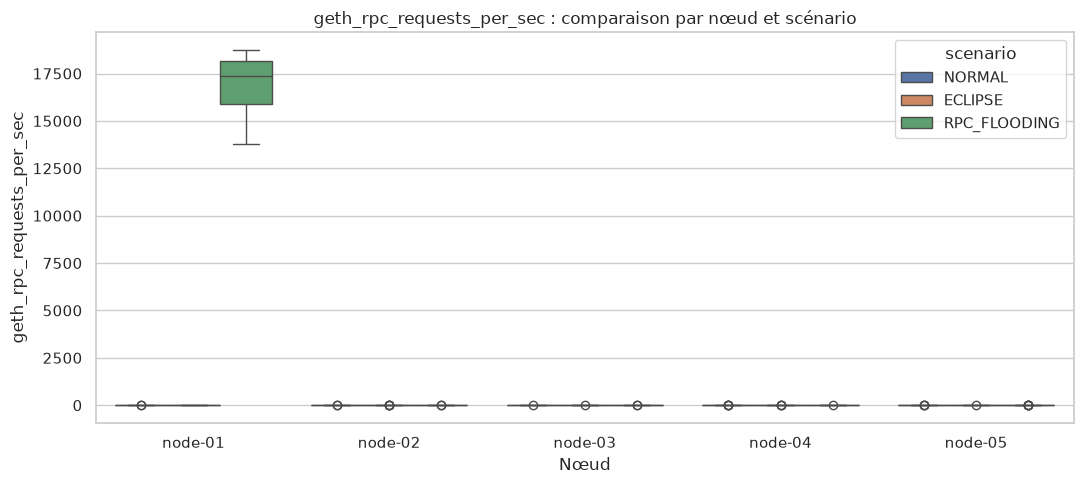

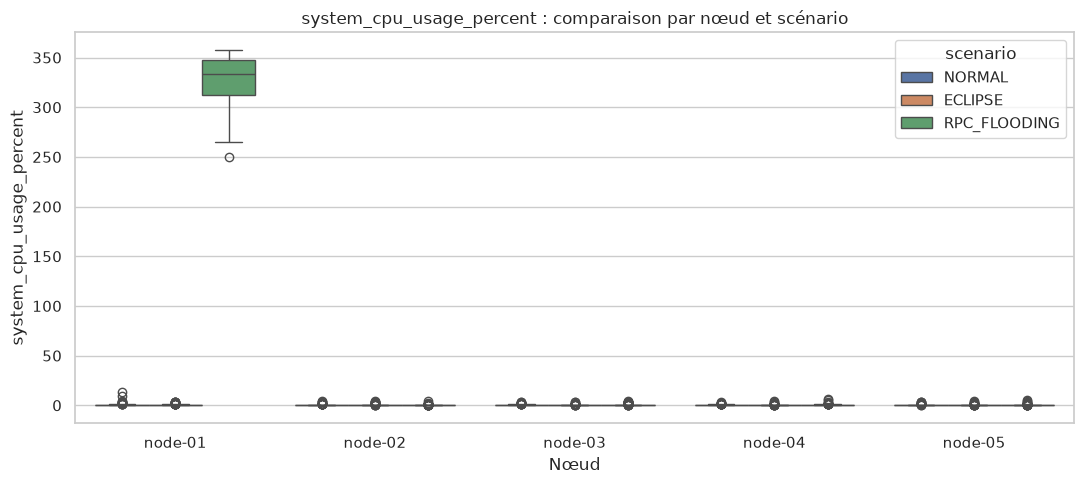

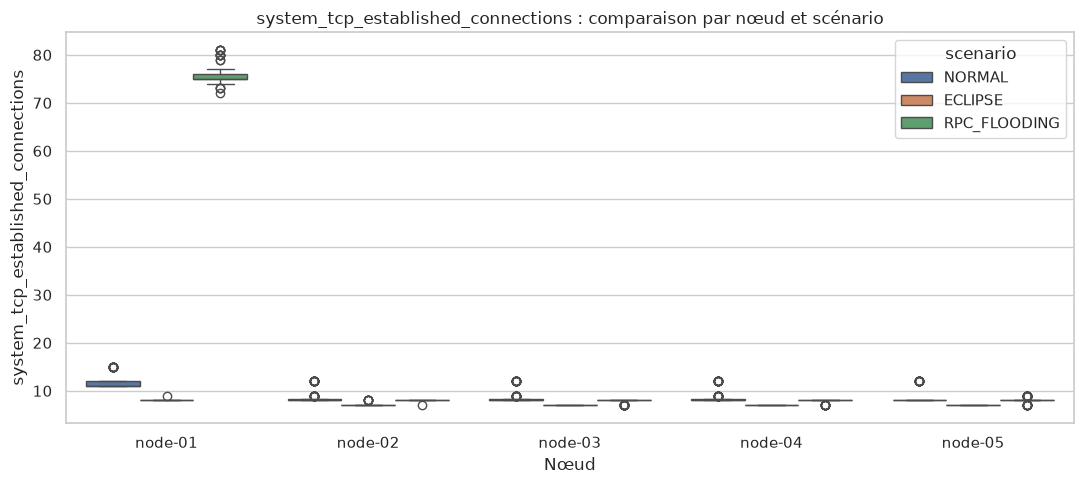

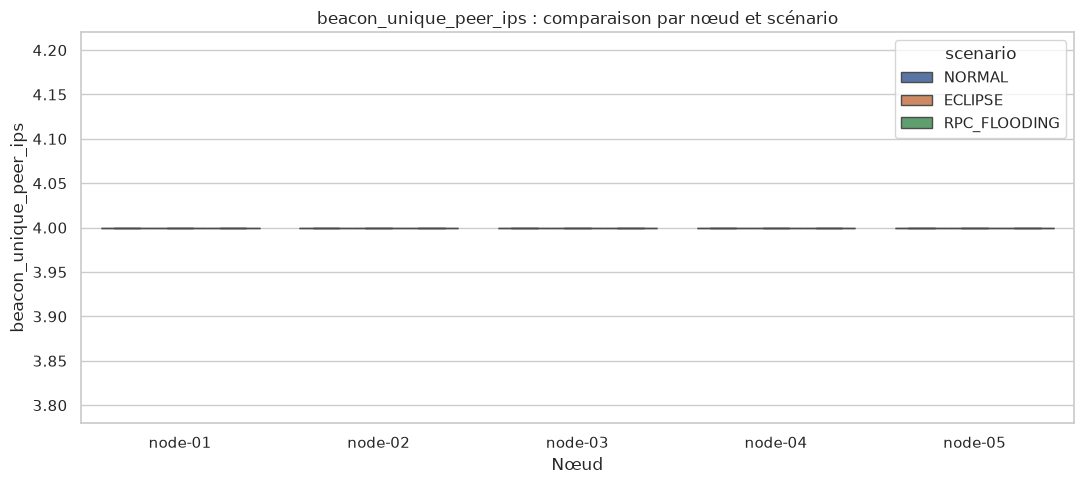

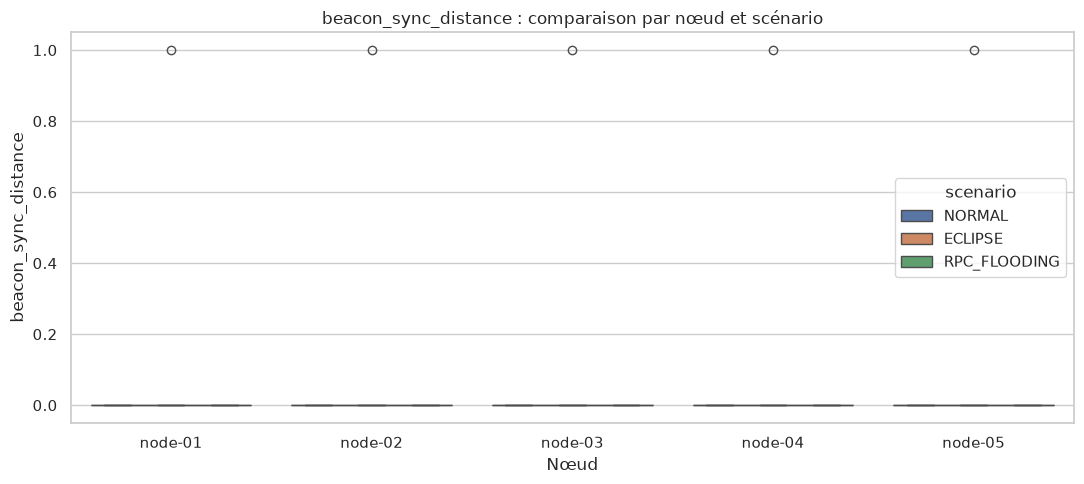

In [12]:
metrics_by_node = [
    c for c in [
        "geth_rpc_requests_per_sec",
        "system_cpu_usage_percent",
        "system_tcp_established_connections",
        "beacon_unique_peer_ips",
        "beacon_sync_distance",
    ]
    if c in df.columns
]

for metric in metrics_by_node:
    plt.figure(figsize=(11, 5))
    sns.boxplot(data=df, x="node_id", y=metric, hue="scenario")
    plt.title(f"{metric} : comparaison par nœud et scénario")
    plt.xlabel("Nœud")
    plt.ylabel(metric)
    plt.tight_layout()
    plt.show()
